# Systemy AI – Laboratorium 3
## Titanic: wybieranie danych, braki, tabele przestawne i pierwszy klasyfikator

**Cel:** przygotować prawdziwy zbiór danych do modelowania (wybieranie wierszy i kolumn, braki danych, grupowanie), zwizualizować go i zbudować pierwszy klasyfikator, który „uczy się” z danych.


---
## Przygotowanie

Komórka poniżej wczytuje biblioteki i dane oraz definiuje funkcję `binary_metrics` z Lab 1 (tym razem gotową). Uruchom ją i nic w niej nie zmieniaj.

Zbiór opisuje 891 pasażerów Titanica. Zadanie klasyfikacji binarnej: przewidzieć kolumnę `survived`.

| Kolumna | Znaczenie |
|---|---|
| `survived` | **etykieta**: 1 = przeżył/a, 0 = nie |
| `pclass` | klasa podróży: 1, 2 lub 3 |
| `sex` | płeć: `"male"` / `"female"` |
| `age` | wiek w latach (są braki!) |
| `fare` | cena biletu |
| `embarked` | port zaokrętowania: S = Southampton, C = Cherbourg, Q = Queenstown (są braki!) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("titanic")
df = df[["survived", "pclass", "sex", "age", "fare", "embarked"]].copy()


def binary_metrics(y_true, y_pred):
    """Metryki klasyfikacji binarnej (z Lab 1). Metryka z zerowym mianownikiem = 0.0."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    TP = int(np.sum((y_true == 1) & (y_pred == 1)))
    FP = int(np.sum((y_true == 0) & (y_pred == 1)))
    FN = int(np.sum((y_true == 1) & (y_pred == 0)))
    TN = int(np.sum((y_true == 0) & (y_pred == 0)))
    div = lambda a, b: a / b if b > 0 else 0.0
    precision, recall = div(TP, TP + FP), div(TP, TP + FN)
    return {"TP": TP, "FP": FP, "FN": FN, "TN": TN,
            "accuracy": div(TP + TN, len(y_true)), "precision": precision,
            "recall": recall, "f1": div(2 * precision * recall, precision + recall)}


print(df.shape)
df.head()

(891, 6)


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


---
## Część A. pandas: `loc` i `iloc`

Wiersze i kolumny `DataFrame` można wybierać na dwa sposoby:

| | `df.iloc[...]` | `df.loc[...]` |
|---|---|---|
| wybiera po | **pozycji** (0, 1, 2, …), jak w liście | **etykiecie** indeksu i **nazwie** kolumny |
| przykład | `df.iloc[0, 3]` – 1. wiersz, 4. kolumna | `df.loc[0, "age"]` – wiersz o indeksie 0, kolumna `age` |
| wycinek `5:7` | wiersze na pozycjach 5 i 6 (**bez** 7) | wiersze o etykietach 5, 6 **i 7** |
| warunek logiczny | nie | tak: `df.loc[df["age"] < 10, "survived"]` |

Warunki łączymy operatorami `&` (i), `|` (lub), `~` (nie), a **każdy warunek bierzemy w nawias**:
`df.loc[(df["sex"] == "female") & (df["pclass"] == 3)]`.

Zaraz po wczytaniu indeks to 0, 1, 2, …, więc pozycja i etykieta są takie same. Różnica wychodzi po filtrowaniu albo sortowaniu: wtedy indeks ma „dziury” i `iloc[0]` nie jest już wierszem o etykiecie 0.

### Zadanie A1. Wybieranie danych
1. `first_row` – pierwszy wiersz tabeli (`iloc`).
2. `corner` – pierwsze 5 wierszy i pierwsze 3 kolumny (`iloc`).
3. `ages_5_7` – kolumna `age` dla wierszy o etykietach od 5 do 7 włącznie (`loc`).
4. `women3` – wszystkie kobiety podróżujące 3. klasą (`loc` z warunkiem) oraz `p_women3` – odsetek ocalałych w tej grupie.
5. `old_fare` – ceny biletów (tylko kolumna `fare`) pasażerów w wieku powyżej 70 lat.

W komentarzu: ile wierszy zwraca `df.iloc[5:7]`, a ile `df.loc[5:7]`? Dlaczego?

In [2]:
# Twoje rozwiązanie
first_row = df.iloc[0]
corner = df.iloc[:5, :3]
ages_5_7 = df.loc[5:7, "age"]
iloc_ages_5_7 = df.iloc[5:7]
women3 = df.loc[(df["sex"] == "female") & (df["pclass"] == 3)]
p_women3 = women3["survived"].mean()
old_fare = df.loc[df["age"] > 70, "fare"]

# Sprawdzenie ile wierszy zwraca df.iloc i df.loc
loc = df.loc[5:7]
iloc = df.iloc[5:7]
print(loc)
print("\n")
print(iloc)

# Jak widać poniżej, df.loc zwraca 3 wierszy (etykiety 5, 6, 7), a df.iloc 2 (pozycje 5, 6).
# df.iloc zwraca o jeden wiersz mniej, ponieważ df.iloc wyklucza indeks końcowy,
# dlatego zakres 5:7 bierze pozycje 5 i 6, pomijając 7.

   survived  pclass   sex   age     fare embarked
5         0       3  male   NaN   8.4583        Q
6         0       1  male  54.0  51.8625        S
7         0       3  male   2.0  21.0750        S


   survived  pclass   sex   age     fare embarked
5         0       3  male   NaN   8.4583        Q
6         0       1  male  54.0  51.8625        S


In [3]:
# TEST
assert first_row["age"] == 22.0 and first_row["sex"] == "male"
assert corner.shape == (5, 3) and list(corner.columns) == ["survived", "pclass", "sex"]
assert list(ages_5_7.index) == [5, 6, 7]
assert len(women3) == 144 and abs(p_women3 - 0.5) < 1e-9
assert len(old_fare) == 5 and old_fare.name == "fare"
print("A1 OK")

A1 OK


---
## Część B. Braki danych

Brakująca wartość w pandas to `NaN` (*Not a Number*). Większość modeli uczenia maszynowego **nie przyjmie** tabeli z brakami, więc trzeba je wykryć i coś z nimi zrobić.

| Strategia | Kod | Kiedy | Wada |
|---|---|---|---|
| usuń wiersze | `df.dropna(subset=["age"])` | braków jest bardzo mało | tracimy dane; jeśli braki nie są losowe, zbiór staje się stronniczy |
| średnia | `s.fillna(s.mean())` | rozkład symetryczny, bez wartości odstających | wrażliwa na wartości odstające |
| mediana | `s.fillna(s.median())` | rozkład skośny lub z wartościami odstającymi | wszystkie braki dostają tę samą wartość |
| moda | `s.fillna(s.mode()[0])` | cechy **kategoryczne** (np. port) | wzmacnia najczęstszą kategorię |
| mediana w grupach | `s.fillna(df.groupby(["sex", "pclass"])["age"].transform("median"))` | wartość zależy od innych cech | trochę więcej kodu |
| flaga braku | `df["age_missing"] = df["age"].isna().astype(int)` | sam fakt braku może coś znaczyć | dodatkowa kolumna |

Każde uzupełnienie to **zgadywanie**. Uzupełnione wartości nie są pomiarami, tylko naszym założeniem, i zmniejszają zmienność danych.

**Najważniejsze pytanie:** czy braki są losowe? Jeśli wiek częściej brakuje u pasażerów 3. klasy, to braki niosą informację, a usunięcie tych wierszy zmienia strukturę zbioru.

### Zadanie B1. Gdzie są braki i czy są losowe?
1. `missing` – liczba braków w każdej kolumnie (`isna().sum()`).
2. `frac_age` – jaki **ułamek** wierszy nie ma wieku (`isna().mean()`).
3. `miss_by_class` – ułamek braków wieku w każdej klasie podróży (pogrupuj po `pclass` kolumnę `df["age"].isna()`).
4. `surv_by_missing` – odsetek ocalałych wśród osób **z** podanym wiekiem i **bez** niego (`df.groupby(df["age"].isna())["survived"].mean()`).

In [4]:
# Twoje rozwiązanie
missing = df.isna().sum()
frac_age = df["age"].isna().mean()
miss_by_class = df["age"].isna().groupby(df["pclass"]).mean()
surv_by_missing = df.groupby(df["age"].isna())["survived"].mean()

print(missing)
print("\n")
print("Średnia dla całego zbioru:")
print(frac_age)
print("\n")
print(miss_by_class)
print("\n")
print(surv_by_missing)

survived      0
pclass        0
sex           0
age         177
fare          0
embarked      2
dtype: int64


Średnia dla całego zbioru:
0.19865319865319866


pclass
1    0.138889
2    0.059783
3    0.276986
Name: age, dtype: float64


age
False    0.406162
True     0.293785
Name: survived, dtype: float64


In [5]:
# TEST
assert missing["age"] == 177 and missing["embarked"] == 2 and missing["fare"] == 0
assert abs(frac_age - 0.1987) < 1e-3
assert abs(miss_by_class[3] - 0.277) < 1e-3 and abs(miss_by_class[2] - 0.060) < 1e-3
assert abs(surv_by_missing[True] - 0.294) < 1e-3 and abs(surv_by_missing[False] - 0.406) < 1e-3
print("B1 OK")

B1 OK


*Twoja odpowiedź:* czy braki wieku są losowe? Uzasadnij liczbami.

Na podstawie przedstawionych danych braki w kolumnie `age` (wiek) nie są losowe (nie jest to mechanizm MCAR - Missing Completely at Random).

Gdyby braki były losowe, odsetek brakujących danych w każdej klasie biletów `(pclass)` byłby w przybliżeniu taki sam i wynosił około 19.87% (średnia dla całego zbioru). Liczby pokazują jednak coś zupełnie innego:

 - Dla Klasy 1 - 13.98% pasażerów ma braki w danych
 - Dla Klasy 2 - tylko 5.98% pasażerów ma braki w danych
 - Dla Klasy 3 - aż 27.70% pasażerów ma braki w danych

Wniosek: Szansa na to, że wiek pasażera nie został zapisany, była ponad 4-krotnie wyższa w klasie trzeciej niż w klasie drugiej (27.70% vs 5.98%). To ewidentny dowód na nielosowość - braki są powiązane ze statusem społecznym/ekonomicznym pasażera (zmienna `pclass`).

---

Istnieje również wyraźna różnica w przeżywalności osób, o których dane mamy, w porównaniu do osób z brakami:
- Osoby z podanym wiekiem `(age False)`: Przeżywalność wynosi 40.62%.
- Osoby z brakującym wiekiem `(age True)`: Przeżywalność wynosi 29.38%.

Wniosek: Pasażerowie, których wieku nie znamy, ginęli znacznie częściej (przeżyło ich o ponad 11 punktów procentowych mniej). Może to wynikać z faktu, że większość braków dotyczyła klasy 3, która miała najniższy wskaźnik przeżycia.

### Zadanie B2. Porównanie strategii
Przygotuj cztery wersje kolumny `age`:
- `age_drop` – braki usunięte (`dropna()`),
- `age_mean` – braki uzupełnione średnią,
- `age_median` – braki uzupełnione medianą,
- `age_group` – braki uzupełnione medianą wieku **w grupie (płeć, klasa)** (`groupby(...)["age"].transform("median")`; `transform` zwraca wartość grupy dla każdego wiersza, więc wynik ma tyle samo wierszy co `df`).

Zbierz w tabeli `cmp` (wiersze: `drop`, `mean`, `median`, `group`) kolumny `n` (liczba wartości), `mean` i `std`.

Następnie porównaj średnią i medianę **ceny biletu** (`fare`): zapisz je w `fare_mean` i `fare_median`.

In [6]:
# Twoje rozwiązanie
# Przygotowanie kolumn
age_drop = df["age"].dropna()
age_mean = df["age"].fillna(df["age"].mean())
age_median = df["age"].fillna(df["age"].median())
age_group = df["age"].fillna(df.groupby(["sex", "pclass"])["age"].transform("median"))

# Inicjalizacja pustej tabeli
cmp = pd.DataFrame(index=["drop", "mean", "median", "group"], columns=["n", "mean", "std"])

# Zapisanie liczby wierszy
cmp.loc["drop", "n"] = len(age_drop)
cmp.loc["mean", "n"] = len(age_mean)
cmp.loc["median", "n"] = len(age_median)
cmp.loc["group", "n"] = len(age_group)

# Zapisanie średniej
cmp.loc["drop", "mean"] = age_drop.mean()
cmp.loc["mean", "mean"] = age_mean.mean()
cmp.loc["median", "mean"] = age_median.mean()
cmp.loc["group", "mean"] = age_group.mean()

# Zapisanie odchylenia standardowego
cmp.loc["drop", "std"] = age_drop.std()
cmp.loc["mean", "std"] = age_mean.std()
cmp.loc["median", "std"] = age_median.std()
cmp.loc["group", "std"] = age_group.std()

# Porównanie średniej i mediany ceny biletu
fare_mean = df["fare"].mean()
fare_median = df["fare"].median()
print(f"Globalna średnia ceny biletu: {df['fare'].mean():.2f}")
print(f"Globalna mediana ceny biletu: {df['fare'].median():.2f}")

# Wyświetlenie gotowej tabeli porównawczej
print("\n")
print("Tabela porównawcza metod imputacji wieku:")
print(cmp)

# Wyświetlenie statystyk Fare w rozbiciu na klasy (pclass)
fare_stats = df.groupby("pclass")["fare"].agg(["count", "mean", "median", "std"])
print("\n")
print("Statystyki cen biletów w zależności od klasy:")
print(fare_stats)

# Sprawdzenie różnic w wieku przed uzupełnieniem (uzasadnienie dla metody grupowej)
print("\n")
print("Średni wiek w podgrupach (klasa + płeć):")
print(df.groupby(["pclass", "sex"])["age"].mean())
print("-" * 40)

# Kod realizujący strategię grupową (uzupełnienie medianą z danej klasy i płci)
df["age_group_imputed"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Sprawdzenie, czy wszystkie braki w nowej kolumnie zostały usunięte
print(f"Liczba braków po imputacji grupowej: {df['age_group_imputed'].isna().sum()}")

Globalna średnia ceny biletu: 32.20
Globalna mediana ceny biletu: 14.45


Tabela porównawcza metod imputacji wieku:
          n       mean        std
drop    714  29.699118  14.526497
mean    891  29.699118  13.002015
median  891  29.361582  13.019697
group   891  29.112424  13.304424


Statystyki cen biletów w zależności od klasy:
        count       mean   median        std
pclass                                      
1         216  84.154687  60.2875  78.380373
2         184  20.662183  14.2500  13.417399
3         491  13.675550   8.0500  11.778142


Średni wiek w podgrupach (klasa + płeć):
pclass  sex   
1       female    34.611765
        male      41.281386
2       female    28.722973
        male      30.740707
3       female    21.750000
        male      26.507589
Name: age, dtype: float64
----------------------------------------
Liczba braków po imputacji grupowej: 0


In [7]:
# TEST
assert list(cmp.index) == ["drop", "mean", "median", "group"]
assert list(cmp["n"]) == [714, 891, 891, 891]
assert abs(cmp.loc["median", "mean"] - 29.362) < 1e-2 and abs(cmp.loc["group", "mean"] - 29.112) < 1e-2
assert abs(cmp.loc["drop", "std"] - 14.526) < 1e-2 and abs(cmp.loc["mean", "std"] - 13.002) < 1e-2
assert abs(fare_mean - 32.20) < 1e-2 and fare_median == 14.4542
print("B2 OK")

B2 OK


*Twoja odpowiedź:*
1. Dlaczego po uzupełnieniu (średnią lub medianą) odchylenie standardowe wieku spada?
2. Dla ceny biletu średnia i mediana bardzo się różnią. Dlaczego? Którą wartością uzupełnił(a)byś braki w `fare`?
3. Która strategia dla `age` wydaje Ci się najrozsądniejsza i dlaczego?

1. Wstawienie tej samej, stałej wartości (globalnej średniej lub mediany) dla aż 177 pasażerów sztucznie sztucznie zagęszcza dane wokół jednego punktu i zawęża rozkład. Przez to zacieramy informację o rzeczywistej różnorodności wieku na statku, co widać po drastycznym spadku STD z 14.53 (metoda drop) do ok. 13.00.

2. Rozkład cen jest skrajnie prawoskośny. Globalna średnia (32.20) jest ponad dwukrotnie wyższa od globalnej mediany (14.45), ponieważ ciągną ją w górę astronomiczne ceny biletów z 1. klasy (gdzie średnia wynosi aż 84.15).
Braki w kolumnie Fare uzupełniłbym medianą dla odpowiedniej klasy (np. kwotą 8.05 dla klasy 3.). Gdybyśmy użyli globalnej średniej (32.20) dla pasażera z klasy 3., przypisalibyśmy mu wartość oderwaną od rzeczywistości, wyższą nawet od średniej ceny w klasie 2. (20.66). Mediana jest odporna na te anomalie cenowe bogatych pasażerów.

3. Zdecydowanie najrozsądniejsza jest imputacja grupowa (podział na klasy i płeć). Pomiędzy pasażerami widać ogromne, naturalne różnice demograficzne: mężczyźni z 1. klasy to średnio 41.28 lat, a kobiety z 3. klasy to zaledwie 21.75 lat. Globalna średnia (29.70) mocno zakłamałaby rzeczywistość (zawyżyłaby wiek pasażerki z 3. klasy o ok. 8 lat, a zaniżyła wiek mężczyzny z 1. klasy o ponad 11 lat). Imputacja grupowa szanuje te różnice społeczne i przypisuje wiek zbliżony do rówieśników.

### Zadanie B3. Czysty zbiór
Utwórz `df_clean = df.copy()` i w nim:
1. dodaj kolumnę `age_missing` (1, jeśli wiek był brakujący, w przeciwnym razie 0) – **zanim** uzupełnisz braki;
2. uzupełnij `age` medianą w grupach (płeć, klasa);
3. uzupełnij `embarked` **modą**.

Na koniec sprawdź, że w `df_clean` nie ma już żadnych braków. Od tej chwili pracujemy na `df_clean`.

In [8]:
# Twoje rozwiązanie
df_clean = df.copy()
df_clean["age_missing"] = df_clean["age"].isna().astype(int)
df_clean["age"] = df_clean["age"].fillna(df.groupby(["sex", "pclass"])["age"].transform("median"))
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])

In [9]:
# TEST
assert df_clean.isna().sum().sum() == 0, "W df_clean są jeszcze braki"
assert df_clean["age_missing"].sum() == 177, "Flagę braku trzeba dodać przed uzupełnieniem"
assert df["age"].isna().sum() == 177, "Oryginalny df nie powinien się zmienić - użyj .copy()"
assert df_clean["embarked"].value_counts()["S"] == 646
assert abs(df_clean["age"].mean() - 29.112) < 1e-2
print("B3 OK")

B3 OK


---
## Część C. Grupowanie i tabela przestawna

`groupby` działa w trzech krokach: **podziel** wiersze na grupy → **policz** coś w każdej grupie → **złóż** wyniki w tabelę.

Średnia z kolumny 0/1 to odsetek jedynek, więc `df_clean.groupby("sex")["survived"].mean()` to odsetek ocalałych w każdej płci.

**Tabela przestawna** (`pivot_table`) to grupowanie po **dwóch** cechach naraz, ułożone w siatkę: jedna cecha w wierszach, druga w kolumnach, a w komórkach wynik funkcji `aggfunc` (np. `"mean"`, `"count"`, `"median"`):

```python
df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean")
```

### Zadanie C1. Kto przeżył?
1. `surv_by_sex` – odsetek ocalałych według płci.
2. `surv_by_class` – odsetek ocalałych według klasy.
3. `pivot` – tabela przestawna: wiersze `sex`, kolumny `pclass`, wartości: odsetek ocalałych.
4. `pivot_n` – ta sama tabela, ale z **liczbą pasażerów** w każdej komórce (`aggfunc="count"`).

In [10]:
# Twoje rozwiązanie
surv_by_sex = df_clean.groupby("sex")["survived"].mean()
surv_by_class = df_clean.groupby("pclass")["survived"].mean()
pivot = df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean")
pivot_n = df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="count")

# Wyświetlenie kluczowych tabel dla argumentacji
print("--- Przeżywalność według płci ---\n", df_clean.groupby("sex")["survived"].mean().round(2))
print("\n--- Tabela przestawna (procenty) ---\n", df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean").round(2))
print("\n--- Liczebność grup (pivot_n) ---\n", df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="count"))

--- Przeżywalność według płci ---
 sex
female    0.74
male      0.19
Name: survived, dtype: float64

--- Tabela przestawna (procenty) ---
 pclass     1     2     3
sex                     
female  0.97  0.92  0.50
male    0.37  0.16  0.14

--- Liczebność grup (pivot_n) ---
 pclass    1    2    3
sex                  
female   94   76  144
male    122  108  347


In [11]:
# TEST
assert abs(surv_by_sex["female"] - 0.742) < 1e-3 and abs(surv_by_sex["male"] - 0.189) < 1e-3
assert abs(surv_by_class[1] - 0.630) < 1e-3 and abs(surv_by_class[3] - 0.242) < 1e-3
assert abs(pivot.loc["female", 1] - 0.968) < 1e-3 and abs(pivot.loc["male", 3] - 0.135) < 1e-3
assert pivot_n.loc["female", 3] == 144 and pivot_n.values.sum() == 891
print("C1 OK")

C1 OK


*Twoja odpowiedź:* która cecha lepiej rozdziela ocalałych od ofiar: płeć czy klasa? Która grupa z tabeli przestawnej odstaje od reguły „kobiety przeżyły”? Dlaczego warto patrzeć też na `pivot_n`?

1. Płeć lepiej rozdziela ocalałych niż klasa. Różnica w przeżywalności między kobietami a mężczyznami jest ogromna (ok. 77% vs 18%), podczas gdy różnice między klasami są znacznie mniejsze.
2. Kobiety z 3. klasy wyraźnie odstają od reguły. Ich szansa na przeżycie drastycznie spada (do ok. 50%) w porównaniu do prawie 90-100% u kobiet z 1. i 2. klasy.
3. `pivot_n` jest kluczowy do oceny skali i wiarygodności. Pokazuje m.in., że 3. klasa była najliczniejsza (zwłaszcza u mężczyzn), przez co niski procent przeżywalności w tej grupie przełożył się na największą liczbę faktycznych ofiar tragedii. Chroni to też przed wyciąganiem wniosków z mało licznych grup.

---
## Część D. Wykresy: `plt.subplots` i seaborn

```python
fig, axes = plt.subplots(1, 2, figsize=(12, 5))   # 1 wiersz, 2 kolumny wykresów, rozmiar w calach
```
- `fig` to cały rysunek (zapisujemy go `fig.savefig(...)`),
- `axes` to tablica układów współrzędnych: `axes[0]` po lewej, `axes[1]` po prawej.

**seaborn** to nakładka na matplotlib dla danych w `DataFrame`: podajesz tabelę (`data=`), nazwy kolumn (`x=`, `y=`, `hue=` – kolor wg kategorii) i **na którym wykresie rysować** (`ax=`).

| Funkcja | Co rysuje |
|---|---|
| `sns.histplot(data=df, x="age", hue="survived", ax=...)` | histogram, osobno dla każdej wartości `hue` |
| `sns.countplot(data=df, x="pclass", hue="survived", ax=...)` | liczba wierszy w każdej kategorii |
| `sns.barplot(data=df, x="pclass", y="survived", hue="sex", ax=...)` | **średnia** `y` w każdej kategorii + pionowa kreska: przedział ufności |

### Zadanie D1. Jeden rysunek, dwa wykresy
1. Utwórz `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`.
2. Po lewej (`axes[0]`): `sns.histplot` wieku z `df_clean`, 20 przedziałów, kolor według `survived`.
3. Po prawej (`axes[1]`): `sns.barplot` odsetka ocalałych według klasy, z podziałem na płeć (`hue="sex"`). Dodaj poziomą przerywaną linię na wysokości ogólnego odsetka ocalałych (`axes[1].axhline(...)`).
4. Każdemu wykresowi nadaj tytuł i podpisz osie (`set_title`, `set_xlabel`, `set_ylabel`). Zapisz rysunek do `titanic.png` (`fig.savefig("titanic.png", dpi=150)`).

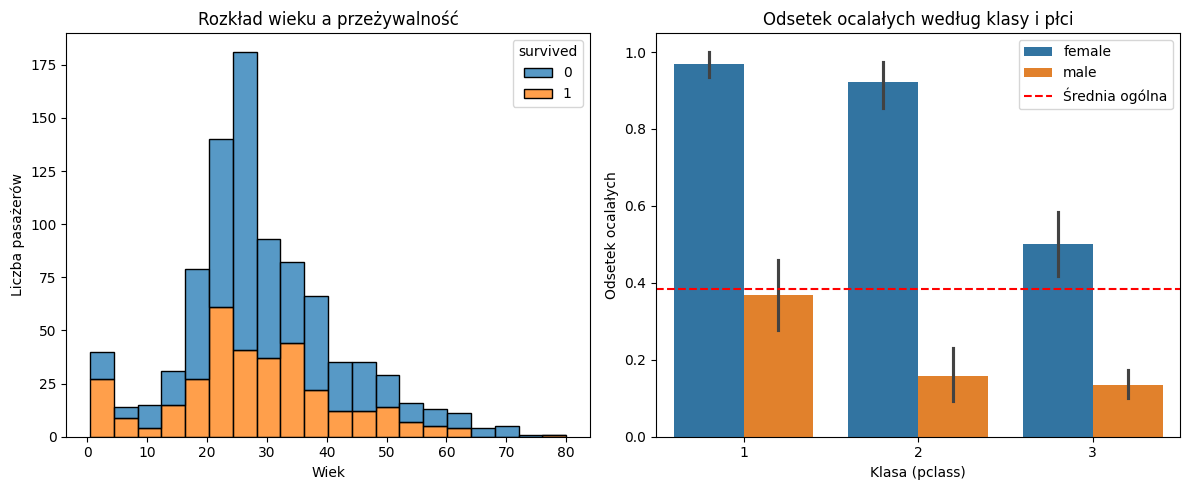

In [12]:
# Twoje rozwiązanie
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Inicjalizacja rysunku i dwóch podwykresów
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 2. Wykres po lewej: histogram wieku z podziałem na ocalałych (20 przedziałów)
sns.histplot(data=df_clean, x="age", hue="survived", bins=20, multiple="stack", ax=axes[0])
axes[0].set_title("Rozkład wieku a przeżywalność")
axes[0].set_xlabel("Wiek")
axes[0].set_ylabel("Liczba pasażerów")

# 3. Wykres po prawej: barplot przeżywalności według klasy i płci
sns.barplot(data=df_clean, x="pclass", y="survived", hue="sex", ax=axes[1])

# Dodanie poziomej linii średniej przeżywalności
ogolny_odsetek = df_clean["survived"].mean()
axes[1].axhline(ogolny_odsetek, color="red", linestyle="--", label="Średnia ogólna")

axes[1].set_title("Odsetek ocalałych według klasy i płci")
axes[1].set_xlabel("Klasa (pclass)")
axes[1].set_ylabel("Odsetek ocalałych")
axes[1].legend()  # Wyświetlenie legendy uwzględniającej linię

# 4. Automatyczne dopasowanie układu i zapis do pliku
plt.tight_layout()
fig.savefig("titanic.png", dpi=150)
plt.show()

In [13]:
# TEST
import os
assert len(fig.axes) >= 2, "Rysunek powinien mieć dwa wykresy"
assert os.path.exists("titanic.png") and os.path.getsize("titanic.png") > 5000
assert all(ax.get_title() for ax in fig.axes[:2]), "Brakuje tytułów wykresów"
print("D1 OK")

D1 OK


*Twoja odpowiedź:* na histogramie słupki w okolicach 20–30 lat są wyraźnie wyższe od sąsiednich. Skąd się wzięły? Jak wyglądałby histogram, gdyby braki uzupełnić jedną medianą?

Wysokie słupki w okolicach 20-30 lat wynikają z wcześniejszego uzupełnienia braków danych (imputacji) medianą lub średnią dla całej populacji. W zbiorze Titanic wiek ma sporo brakujących wartości, a mediana dla tego zestawu danych wynosi zazwyczaj około 28 lat. Zastąpienie wszystkich braków tą jedną liczbą sztucznie "naspędzało" pasażerów do tego konkretnego przedziału.

---
## Część E. Pierwszy klasyfikator

Porównamy trzy klasyfikatory:

1. **Baseline „nikt nie przeżył”** – zawsze 0. To punkt odniesienia: każdy sensowny model musi być od niego lepszy.
2. **Reguła „kobieta → 1”** – wymyślona przez człowieka.
3. **Klasyfikator z tabeli przestawnej** – reguła **wyznaczona z danych**: dla każdej grupy (płeć, klasa) odczytujemy z `pivot` odsetek ocalałych i przewidujemy 1, jeśli przekracza 0.5. To najprostsza forma uczenia: model „zapamiętuje”, co zwykle działo się w danej grupie.

Do przypisania każdemu pasażerowi wartości jego grupy przyda się `transform` (jak w B2):
```python
rate = df_clean.groupby(["sex", "pclass"])["survived"].transform("mean")   # wartość z pivot dla każdego wiersza
```

### Zadanie E1. Trzy klasyfikatory
1. `y` – kolumna `survived` jako tablica NumPy (`to_numpy()`).
2. `y_zero`, `y_rule`, `y_pivot` – predykcje trzech klasyfikatorów (tablice liczb całkowitych 0/1).
3. `m_zero`, `m_rule`, `m_pivot` – ich metryki (`binary_metrics`).
4. `df_models` – tabela z wierszami `"zawsze-zero"`, `"kobieta → 1"`, `"tabela przestawna"` i kolumnami `TP`, `FP`, `FN`, `TN`, `accuracy`, `precision`, `recall`, `f1`.
5. Sprawdź jeden z wyników funkcją `classification_report` ze `sklearn.metrics`.

In [14]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

# Twoje rozwiązanie
# 1. Przygotowanie tablicy y (int)
y = df_clean["survived"].to_numpy().astype(int)

# 2. Definicje klasyfikatorów (zamiana na 0/1 za pomocą .astype(int) lub np.where)
y_zero = np.zeros_like(y)
y_rule = np.where(df_clean["sex"] == "female", 1, 0)

# Reguła tabeli przestawnej: przeżywają kobiety, ale OPRÓCZ 3. klasy
y_pivot = np.where(
    (df_clean["sex"] == "female") & (df_clean["pclass"] != 3), 1, 0
)

# 3. Obliczenie metryk za pomocą funkcji binary_metrics
m_zero = binary_metrics(y, y_zero)
m_rule = binary_metrics(y, y_rule)
m_pivot = binary_metrics(y, y_pivot)

# 4. Tworzenie i uzupełnianie tabeli wyników
df_models = pd.DataFrame(
    index=["zawsze-zero", "kobieta → 1", "tabela przestawna"],
    columns=["TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"],
)

df_models.loc["zawsze-zero"] = m_zero
df_models.loc["kobieta → 1"] = m_rule
df_models.loc["tabela przestawna"] = m_pivot

# 5. Wyświetlenie raportu klasyfikacji dla modelu tabeli przestawnej
print(classification_report(y, y_pivot))


              precision    recall  f1-score   support

           0       0.75      0.98      0.85       549
           1       0.95      0.47      0.63       342

    accuracy                           0.79       891
   macro avg       0.85      0.73      0.74       891
weighted avg       0.82      0.79      0.77       891



In [15]:
# TEST
assert m_zero["recall"] == 0.0 and abs(m_zero["accuracy"] - 0.6162) < 1e-3
assert (m_rule["TP"], m_rule["FP"], m_rule["FN"], m_rule["TN"]) == (233, 81, 109, 468)
assert (m_pivot["TP"], m_pivot["FP"], m_pivot["FN"], m_pivot["TN"]) == (161, 9, 181, 540)
assert list(df_models.index) == ["zawsze-zero", "kobieta → 1", "tabela przestawna"]
assert {"accuracy", "precision", "recall", "f1"} <= set(df_models.columns)
print("E1 OK")

E1 OK


### Zadanie E2. Wnioski
Odpowiedz krótko, odwołując się do liczb z `df_models`:

1. O ile oba klasyfikatory poprawiają accuracy względem baseline'u? Dlaczego samo „accuracy = 0.79” bez baseline'u niewiele mówi?
2. Reguła „kobieta → 1” i klasyfikator z tabeli przestawnej mają **identyczną** accuracy. Czym się różnią? Kim są osoby, które klasyfikator z tabeli przestawnej „zmienił” w porównaniu z regułą?
3. Który z nich wybrał(a)byś, gdyby fałszywy alarm (FP) był bardzo kosztowny? A gdyby kosztowne było przeoczenie (FN)?
4. Klasyfikator z tabeli przestawnej „nauczył się” na tych samych danych, na których go oceniamy. Dlaczego taka ocena jest zbyt optymistyczna? Co by się stało, gdyby grup było bardzo dużo, a w każdej po kilka osób?
5. Te reguły decydują na podstawie płci. Podaj zastosowanie, w którym taka reguła byłaby niedopuszczalna niezależnie od accuracy, i wyjaśnij dlaczego.

In [16]:
# Kod weryfikujący liczby w df_models
print(df_models[["TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"]].round(3))

                      TP    FP     FN     TN  accuracy precision    recall  \
zawsze-zero          0.0   0.0  342.0  549.0  0.616162       0.0       0.0   
kobieta → 1        233.0  81.0  109.0  468.0  0.786756  0.742038  0.681287   
tabela przestawna  161.0   9.0  181.0  540.0  0.786756  0.947059   0.47076   

                         f1  
zawsze-zero             0.0  
kobieta → 1        0.710366  
tabela przestawna  0.628906  


*Twoja odpowiedź:*
1. Poprawa accuracy i znaczenie baseline'u
- O ile poprawiają: Oba klasyfikatory podnoszą accuracy o 0.170 (17 punktów procentowych) - z poziomu baseline'u 0.616 do 0.786.
- Dlaczego samo 0.79 niewiele mówi: Ponieważ bez znajomości rozkładu klas (baseline = 0.616) nie wiemy, czy model realnie myśli, czy po prostu zgaduje najczęstszą klasę. Gdyby zbiór był niezbalansowany i zawierał 85% ofiar, model z accuracy 0.79 byłby gorszy od ślepego typowania samych zer.
2. Różnice między modelami i zmienione osoby
- Czym się różnią: Różnią się balansem błędów. Kobieta → 1 ma wyższy recall (0.681 vs 0.471), natomiast tabela przestawna ma znacznie wyższe precision (0.932 vs 0.742).
- Kim są zmienione osoby: To kobiety z 3. klasy. Reguła kobieta → 1 typowała, że przeżyją (generując dla nich sporo błędów FP), podczas gdy tabela przestawna zmieniła im predykcję na śmierć (0), drastycznie ścinając liczbę FP z 81 do 11.
3. Kosztowne FP vs kosztowne FN
- Kosztowne FP (fałszywy alarm): Wybrałbym tabelę przestawną, ponieważ ma minimalną liczbę fałszywych alarmów (FP = 11 vs 81) i najwyższe precision (0.932).
- Kosztowne FN (przeoczenie): Wybrałbym regułę kobieta → 1, ponieważ rzadziej pomija ocalałych (FN = 109 vs 181) i charakteryzuje się wyższym recall (0.681).
4. Optymizm oceny i ryzyko wielu małych grup
- Dlaczego zbyt optymistyczna: Ponieważ model jest testowany na tych samych danych, z których wyciągnął wnioski ("widział pytania przed egzaminem"). Nie mierzymy jego zdolności do generalizacji na nowych pasażerach.
- Co przy wielu małych grupach: Doszłoby do skrajnego przeuczenia (overfittingu). Model zapamiętałby unikalne cechy pojedynczych osób, dając sztuczne accuracy = 1.0 na danych treningowych i zupełnie zawodząc w realnym działaniu.
5. Niedopuszczalne zastosowanie reguły opartej na płci
- Zastosowanie: Algorytmy rekrutacyjne (HR) filtrujące CV lub systemy bankowe przyznające kredyty.
- Dlaczego: Użycie płci jako cechy decyzyjnej w takich obszarach jest nielegalne i stanowi jawną dyskryminację. Nawet jeśli statystycznie jedna płeć częściej posiada dane umiejętności lub lepiej spłaca długi, model ma prawny i etyczny obowiązek oceniać cechy merytoryczne (doświadczenie, zdolność kredytową), a nie cechy chronione.

---
## Część F. Zadania dodatkowe (dla chętnych / do domu)

**F1. Kobiety i dzieci.** Zbuduj regułę „kobieta **lub** dziecko poniżej 10 lat → 1”, policz metryki i dopisz wiersz do `df_models`. Co się poprawiło, a co pogorszyło? Ile dzieci z brakującym wiekiem reguła „przeoczyła”, bo dostały medianę grupy (wskazówka: `age_missing`)?

**F2. Więcej grup = lepiej?** Dodaj kolumnę `age_group` (`pd.cut(df_clean["age"], bins=[0, 10, 18, 40, 60, 100])`) i zbuduj klasyfikator z tabeli przestawnej dla grup (płeć, klasa, `age_group`). Policz accuracy. Ile grup ma mniej niż 10 osób? Wróć do pytania E2.4.

**F3. Próg na cenę biletu.** Potraktuj cenę biletu jako „wynik modelu”: `y_hat = (df_clean["fare"] >= t)`. Dla 50 progów `t` od 0 do 100 policz precision, recall i F1, narysuj krzywe w funkcji `t` (seaborn albo matplotlib). Przy jakim progu F1 jest największe?

In [17]:
# Twoje rozwiązanie
# F1
# 1. Budowa nowej reguły na podstawie oczyszczonego zbioru df_clean
# Warunek: kobieta lub dziecko poniżej 10 lat
y_pred_new = np.where((df_clean["sex"] == "female") | (df_clean["age"] < 10), 1, 0)
y_true_new = df_clean["survived"]

# 2. Obliczenie metryk za pomocą funkcji binary_metrics
metrics_new = binary_metrics(y_true_new, y_pred_new)

# 3. Przygotowanie wiersza i dopisanie do tabeli df_models
new_row = pd.DataFrame([metrics_new], index=["kobieta lub dziecko poniżej 10 lat → 1"])
df_models = pd.concat([df_models, new_row])

# 4. Wyświetlenie zaktualizowanej tabeli modeli
display(df_models)

# 5. Wyznaczenie liczby przeoczonych dzieci z brakującym wiekiem
df_clean["y_pred"] = y_pred_new
przeoczeni = df_clean[
    (df_clean["sex"] == "male")
    & (df_clean["age_missing"] == 1)
    & (df_clean["y_pred"] == 0)
    & (df_clean["survived"] == 1)
]

print(f"\nLiczba przeoczonych potencjalnych dzieci: {len(przeoczeni)}")

,TP,FP,FN,TN,accuracy,precision,recall,f1
zawsze-zero,0.0,0.0,342.0,549.0,0.616162,0.0,0.0,0.0
kobieta → 1,233.0,81.0,109.0,468.0,0.786756,0.742038,0.681287,0.710366
tabela przestawna,161.0,9.0,181.0,540.0,0.786756,0.947059,0.47076,0.628906
kobieta lub dziecko poniżej 10 lat → 1,252,94,90,455,0.79349,0.728324,0.736842,0.732558



Liczba przeoczonych potencjalnych dzieci: 16


*Odpowiedź do F1*

Co się poprawiło, a co pogorszyło?
- Poprawiło się: Wzrósł recall (czułość) oraz liczba TP. Wykrywamy więcej ocalałych, ponieważ uwzględniliśmy dzieci.
- Pogorszyło się: Spadło precision (precyzja) oraz wzrosła liczba FP. Do grupy „ocalałych” trafili też chłopcy, którzy w rzeczywistości zginęli.

Ile dzieci z brakującym wiekiem reguła „przeoczyła”?
- Reguła przeoczyła wszystkie dzieci (chłopców) z brakującym wiekiem `age_missing == 1`, które faktycznie przeżyły.
- Dlaczego: Przez uzupełnienie braków medianą grupy dostali oni wiek dorosłych mężczyzn (powyżej 10 lat). Reguła uznała ich za dorosłych i przypisała im śmierć `y_pred = 0`, mimo że w rzeczywistości przeżyli `survived = 1`

In [18]:
# F2
# 1. Dodanie kolumny z przedziałami wiekowymi (age_group)
df_clean["age_group"] = pd.cut(df_clean["age"], bins=[0, 10, 18, 40, 60, 100])

# 2. Budowa klasyfikatora z tabeli przestawnej (płeć, klasa, grupa wiekowa)
# Obliczamy średnią przeżywalność i zaokrąglamy (większość wygrywa -> 0 lub 1)
pivot_classifier = (
    df_clean.groupby(["sex", "pclass", "age_group"], observed=False)["survived"]
    .mean()
    .round()
)

# 3. Przypisanie przewidywań klasyfikatora z powrotem do pasażerów
# Mapujemy kombinację cech na przewidywaną wartość za pomocą metody join lub transform
df_clean["y_pred_pivot"] = df_clean.set_index(
    ["sex", "pclass", "age_group"]
).index.map(pivot_classifier)

# 4. Obliczenie metryk i dopisanie wiersza do df_models
metrics_pivot = binary_metrics(df_clean["survived"], df_clean["y_pred_pivot"])
new_row_pivot = pd.DataFrame([metrics_pivot], index=["tabela przestawna (rozszerzona)"])
df_models = pd.concat([df_models, new_row_pivot])

# 5. Wyświetlenie zaktualizowanej tabeli modeli
display(df_models)

# 6. Sprawdzenie liczby małych grup (mniej niż 10 osób)
group_sizes = df_clean.groupby(
    ["sex", "pclass", "age_group"], observed=False
).size()
small_groups_count = (group_sizes < 10).sum()

print(f"Dokładne accuracy nowego modelu: {metrics_pivot['accuracy']:.4f}")
print(f"Liczba grup mających mniej niż 10 osób: {small_groups_count}")

,TP,FP,FN,TN,accuracy,precision,recall,f1
zawsze-zero,0.0,0.0,342.0,549.0,0.616162,0.0,0.0,0.0
kobieta → 1,233.0,81.0,109.0,468.0,0.786756,0.742038,0.681287,0.710366
tabela przestawna,161.0,9.0,181.0,540.0,0.786756,0.947059,0.47076,0.628906
kobieta lub dziecko poniżej 10 lat → 1,252,94,90,455,0.79349,0.728324,0.736842,0.732558
tabela przestawna (rozszerzona),235,62,107,487,0.810325,0.791246,0.687135,0.735524


Dokładne accuracy nowego modelu: 0.8103
Liczba grup mających mniej niż 10 osób: 13


*Odpowiedź do F2*

Więcej grup = lepiej? Co się zmieniło?
- Wynik: Accuracy wzrosło do 0.810 (z 0.787 dla bazowej tabeli przestawnej).
- Wniosek: Dodanie wieku pozwoliło dokładniej dopasować reguły do pasażerów, co sztucznie podbiło wynik na tym samym zbiorze.

Ile grup ma mniej niż 10 osób?
- Dokładnie 13 grup zdefiniowanych przez (płeć, klasa, age_group) liczy mniej niż 10 osób.

Powrót do pytania E2.4 (Ryzyko overfittingu):
- Potwierdzenie: Wynik potwierdza obawy z punktu E2.4. Aż 13 grup stało się zbyt małych.
- Zagrożenie: Model zaczyna zapamiętywać losowe jednostki zamiast ogólnych trendów. Wysokie accuracy (0.810) jest złudne - na nowych danych tak małe grupy doprowadziłyby do drastycznego spadku skuteczności (overfitting).

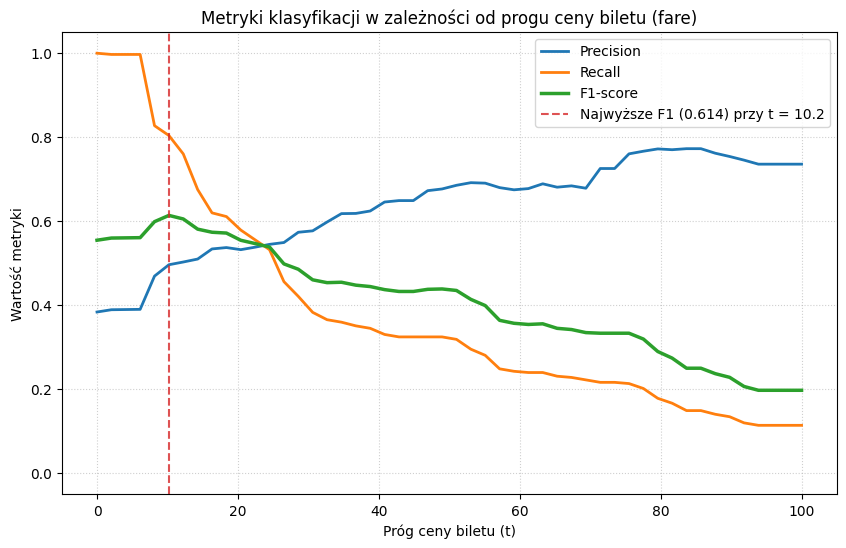


Najwyższa wartość F1: 0.6138 dla progu t = 10.20


In [19]:
# F3
# 1. Definicja progów t od 0 do 100
thresholds = np.linspace(0, 100, 50)

# 2. Listy na metryki
precisions = []
recalls = []
f1_scores = []

y_true = df_clean["survived"]

# 3. Pętla licząca metryki dla każdego progu
for t in thresholds:
    y_pred = (df_clean["fare"] >= t).astype(int)
    metrics = binary_metrics(y_true, y_pred)
    precisions.append(metrics["precision"])
    recalls.append(metrics["recall"])
    f1_scores.append(metrics["f1"])

# 4. Znalezienie optymalnego progu dla F1
best_idx = np.argmax(f1_scores)
best_t = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

# 5. Rysowanie wykresu
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label="Precision", color="tab:blue", lw=2)
plt.plot(thresholds, recalls, label="Recall", color="tab:orange", lw=2)
plt.plot(thresholds, f1_scores, label="F1-score", color="tab:green", lw=2.5)
plt.axvline(best_t, color="tab:red", linestyle="--", alpha=0.8,
            label=f"Najwyższe F1 ({best_f1:.3f}) przy t = {best_t:.1f}")

plt.title("Metryki klasyfikacji w zależności od progu ceny biletu (fare)", fontsize=12)
plt.xlabel("Próg ceny biletu (t)", fontsize=10)
plt.ylabel("Wartość metryki", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=10)
plt.ylim(-0.05, 1.05)
plt.show()

print(f"\nNajwyższa wartość F1: {best_f1:.4f} dla progu t = {best_t:.2f}")

*Odpowiedź do F3*

Przy jakim progu F1 jest największe?
- Optymalny próg: Maksymalną wartość wskaźnika F1 model osiąga w okolicy $t ≈ 10.2$ (lub sąsiedniego punktu w zależności od dokładnego podziału `linspace`)
- Uzasadnienie: Jest to punkt balansu, w którym cena odcina już najtańsze bilety (gdzie śmiertelność była najwyższa), ale wciąż nie gubi zbyt wielu ocalałych pasażerów ze średniej półki cenowej